# 2 · How Much Each Item Sells

Give every SKU in the catalogue a share of the shop's sales (all shares add to 1). Each share is built from four
choices a shop owner would recognise: **category → product → brand → pack size**.

**Done when:** `my_popularity` matches the reference (`same as the reference: True`).

In [1]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.catalog_data import CATEGORIES
from thilimarketbasket.generate import make_catalog, popularity as reference_popularity

catalog = make_catalog()
print(f"{len(catalog):,} SKUs in the catalogue")

1,000 SKUs in the catalogue


## The weights

Every level in `catalog_data.py` has *relative* weights: 20 vs 10 just means "twice as much". Pulses as an example:

In [2]:
pulses = CATEGORIES["Pulses"]
print("category weight:", pulses["weight"], "(out of", sum(c["weight"] for c in CATEGORIES.values()), "across all categories)")
print("brand weights: ", pulses["brands"])
print("size weights:  ", pulses["sizes"])
print("product weights:")
for product in pulses["products"][:4]:
    print("  ", product)

category weight: 8 (out of 101 across all categories)
brand weights:  {'Surya Grains': 8, 'Kaveri Valley': 5, 'Annadata': 3, 'Maitri Foods': 2, 'Shubham Select': 1.5, 'Pragati': 1}
size weights:   {'500 g': 3, '1 kg': 6, '5 kg': 2}
product weights:
   ('Toor Dal', 20)
   ('Moong Dal', 10)
   ('Chana Dal', 8)
   ('Urad Dal', 8)


## Weights → shares

A share = this option's weight ÷ the total weight of the options **the shop actually stocks** at that level.
Then multiply down the chain:

`SKU share = category share × product share × brand share × size share`

Dividing only over stocked options matters: Toor Dal here has 4 of the 6 Pulses brands, and dividing by all 6 would
hand a quarter of Toor Dal sales to brands that aren't on the shelf.

In [3]:
def fraction(weights, chosen, stocked):
    """The share of `chosen` among the `stocked` options, using the weights given."""
    return weights[chosen] / sum(weights[option] for option in stocked)


def level_shares(item, catalog, categories=CATEGORIES):
    """The four fractions for one SKU: category, product, brand, size. Each is a share of its own level."""
    spec = categories[item.category]

    products_here = [it for it in catalog if it.category == item.category]
    stocked_products = {it.base for it in products_here}
    product_weights, size_weights = {}, {}
    for product in spec["products"]:
        name, weight = product[0], product[1]
        product_weights[name] = weight
        size_weights[name] = product[2] if len(product) == 3 else spec["sizes"]

    category = spec["weight"] / sum(c["weight"] for c in categories.values())
    product = fraction(product_weights, item.base, stocked_products)

    if item.brand is None:       # sold loose: no brand to choose
        brand = 1.0
    else:
        stocked_brands = {it.brand for it in products_here if it.base == item.base}
        brand = fraction(spec["brands"], item.brand, stocked_brands)

    stocked_sizes = {it.size for it in products_here if it.base == item.base and it.brand == item.brand}
    size = fraction(size_weights[item.base], item.size, stocked_sizes)
    return category, product, brand, size

In [4]:
def my_popularity(catalog, categories=CATEGORIES):
    """One share per SKU, in catalogue order, adding up to 1."""
    shares = np.array([np.prod(level_shares(item, catalog, categories)) for item in catalog])
    return shares / shares.sum()


shares = my_popularity(catalog)
print("shares add up to", round(shares.sum(), 6))

shares add up to 1.0


The final `/ shares.sum()` is just a safety net — with every product stocked (section 1 guarantees that) the
product already sums to 1.

## Check against the reference

In [5]:
reference = reference_popularity(catalog)
print("same as the reference:", np.allclose(shares, reference, rtol=0, atol=1e-12))
print("largest difference:   ", float(np.abs(shares - reference).max()))

same as the reference: True
largest difference:    0.0


## One SKU, step by step

In [6]:
sku = next(item for item in catalog if item.name == "Kaveri Valley Toor Dal 1 kg")
c, p, b, s = level_shares(sku, catalog)

print(sku.name, "\n")
print(f"  category share  {c:.4f}   Pulses is {c:.1%} of the shop's sales")
print(f"  product share   {p:.4f}   Toor Dal is {p:.1%} of Pulses")
print(f"  brand share     {b:.4f}   Kaveri Valley is {b:.1%} of the Toor Dal that is stocked")
print(f"  size share      {s:.4f}   1 kg is {s:.1%} of Kaveri Valley Toor Dal")
print(f"  {'':16}{'-' * 8}")
print(f"  SKU share       {c * p * b * s:.5f}  = {c * p * b * s:.2%} of all sales")

Kaveri Valley Toor Dal 1 kg 

  category share  0.0792   Pulses is 7.9% of the shop's sales
  product share   0.2899   Toor Dal is 29.0% of Pulses
  brand share     0.3226   Kaveri Valley is 32.3% of the Toor Dal that is stocked
  size share      0.5455   1 kg is 54.5% of Kaveri Valley Toor Dal
                  --------
  SKU share       0.00404  = 0.40% of all sales


The four levels as pictures — the highlighted bar is this SKU's pick at each level.

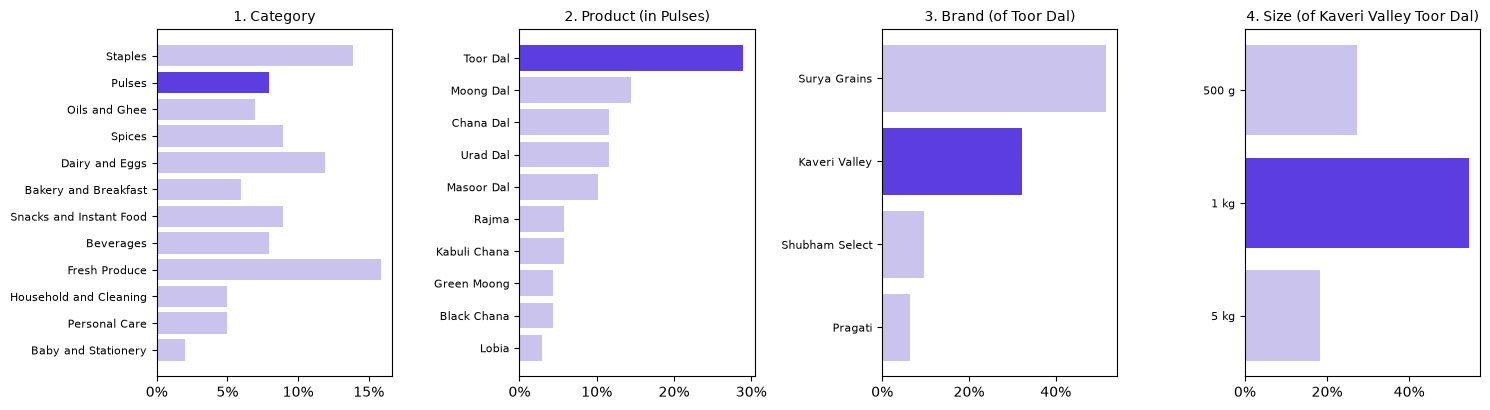

In [7]:
def bars(ax, labels, values, highlight, title):
    colors = ["#5b3de0" if label == highlight else "#c9c3ee" for label in labels]
    ax.barh(range(len(labels)), values, color=colors)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")


stocked_toor = {it.brand for it in catalog if it.base == "Toor Dal"}
stocked_sizes = {it.size for it in catalog if it.base == "Toor Dal" and it.brand == "Kaveri Valley"}

cat_w = {name: spec["weight"] for name, spec in CATEGORIES.items()}
prod_w = {p[0]: p[1] for p in pulses["products"]}
brand_w = {k: v for k, v in pulses["brands"].items() if k in stocked_toor}
size_w = {k: v for k, v in pulses["sizes"].items() if k in stocked_sizes}

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, weights, highlight, title in zip(
        axes, (cat_w, prod_w, brand_w, size_w), ("Pulses", "Toor Dal", "Kaveri Valley", "1 kg"),
        ("1. Category", "2. Product (in Pulses)", "3. Brand (of Toor Dal)", "4. Size (of Kaveri Valley Toor Dal)")):
    total = sum(weights.values())
    bars(ax, list(weights), [w / total for w in weights.values()], highlight, title)
plt.tight_layout()
plt.show()

## Why normalise each level separately

If the shop stocks more brands, Toor Dal's *total* share shouldn't change — people buy dal because they need dal; the
brands only decide who gets the sale. (300-item shops, since 1 brand/product only allows 305 SKUs.)

In [8]:
def product_share(catalog, shares, base):
    return sum(share for item, share in zip(catalog, shares) if item.base == base)

for brands in (1, 2, 4, 6):
    other = make_catalog(n_items=300, brands_per_product=brands)
    other_shares = reference_popularity(other)
    print(f"{brands} brand(s) per product: {len(other):>5,} items, "
          f"Toor Dal = {product_share(other, other_shares, 'Toor Dal'):.4f} of sales, "
          f"Milk = {product_share(other, other_shares, 'Milk'):.4f}")

1 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475
2 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475
4 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475
6 brand(s) per product:   300 items, Toor Dal = 0.0230 of sales, Milk = 0.0475


Same 2.3% and 4.8% every time: a choice at one level doesn't leak into another.

## The long tail

By category first:

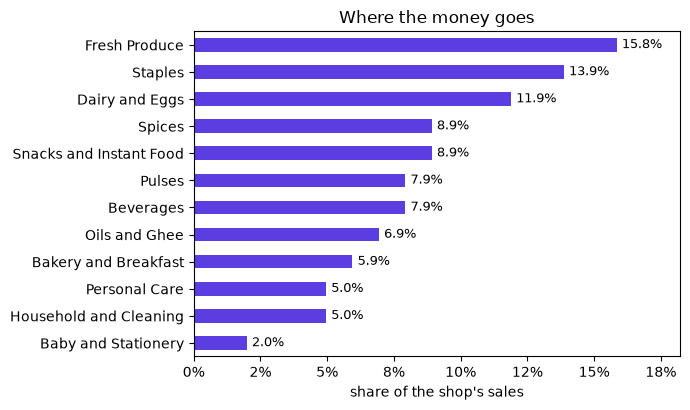

In [9]:
df = pd.DataFrame([vars(item) for item in catalog])
df["share"] = shares

by_category = df.groupby("category")["share"].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
by_category.plot.barh(ax=ax, color="#5b3de0")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("share of the shop's sales")
ax.set_ylabel("")
ax.set_title("Where the money goes")
for position, value in enumerate(by_category):
    ax.text(value + 0.002, position, f"{value:.1%}", va="center", fontsize=9)
ax.set_xlim(0, by_category.max() * 1.15)
plt.tight_layout()
plt.show()

Then every SKU ranked by share:

In [10]:
ranked = np.sort(shares)[::-1]
rank = np.arange(1, len(ranked) + 1)

print("The ten best sellers:")
print(df.sort_values("share", ascending=False).head(10)[["name", "share"]].to_string(index=False, float_format=lambda x: f"{x:.2%}"))
print("\nThe five slowest:")
print(df.sort_values("share").head(5)[["name", "share"]].to_string(index=False, float_format=lambda x: f"{x:.4%}"))
print(f"\nbest seller / slowest seller: {ranked[0] / ranked[-1]:.0f} to 1")

The ten best sellers:
                      name  share
                Onion 1 kg  1.41%
               Tomato 1 kg  1.32%
               Potato 1 kg  1.32%
   Gokul Fresh Milk 500 ml  1.27%
    Coriander Leaves bunch  1.19%
Surya Grains Toor Dal 1 kg  1.18%
               Onion 500 g  1.13%
              Tomato 500 g  1.05%
              Potato 500 g  1.05%
   Kaveri Valley Salt 1 kg  1.02%

The five slowest:
                          name   share
            Pragati Lobia 5 kg 0.0026%
   Amrit Kalash Vanaspati 5 kg 0.0028%
    Tulsi Tara Hair Oil 500 ml 0.0030%
Tulsi Tara Talcum Powder 200 g 0.0030%
 Kids Korner Baby Cereal 400 g 0.0032%

best seller / slowest seller: 541 to 1


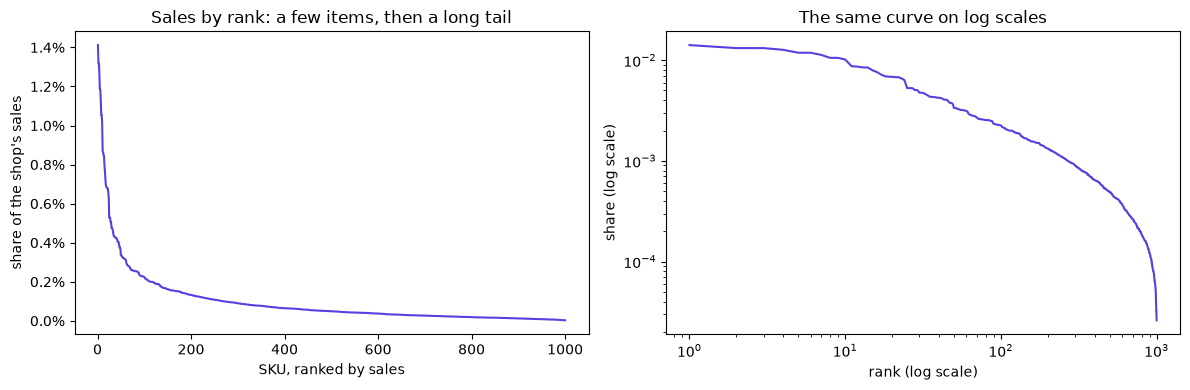

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(rank, ranked, color="#5b3de0")
axes[0].set_xlabel("SKU, ranked by sales")
axes[0].set_ylabel("share of the shop's sales")
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_title("Sales by rank: a few items, then a long tail")

axes[1].loglog(rank, ranked, color="#5b3de0")
axes[1].set_xlabel("rank (log scale)")
axes[1].set_ylabel("share (log scale)")
axes[1].set_title("The same curve on log scales")

plt.tight_layout()
plt.show()

## How concentrated are sales?

Sort best-first, keep a running total (`np.cumsum`), and read it at "top x% of SKUs". If every SKU sold equally the
top 20% would make exactly 20% of sales.

top   1% of SKUs ( 10 items) make 12% of sales
top   5% of SKUs ( 50 items) make 34% of sales
top  10% of SKUs (100 items) make 47% of sales
top  20% of SKUs (200 items) make 64% of sales
top  50% of SKUs (500 items) make 88% of sales

114 SKUs make half the sales, 365 make 80%


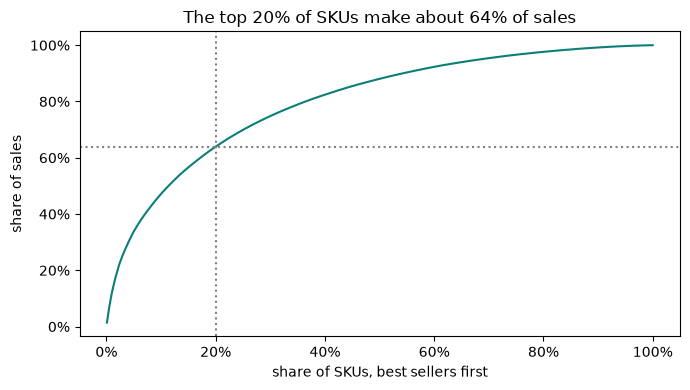

In [12]:
from thilimarketbasket.generate import head_share

cumulative = np.cumsum(ranked)
for top in (0.01, 0.05, 0.10, 0.20, 0.50):
    print(f"top {top:>4.0%} of SKUs ({int(top * len(ranked)):>3} items) make {head_share(shares, top):.0%} of sales")

half = int((cumulative < 0.5).sum() + 1)
eighty = int((cumulative < 0.8).sum() + 1)
print(f"\n{half} SKUs make half the sales, {eighty} make 80%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rank / len(rank), cumulative, color="#0b7f77")
ax.axvline(0.2, color="grey", linestyle=":")
ax.axhline(head_share(shares, 0.2), color="grey", linestyle=":")
ax.set_xlabel("share of SKUs, best sellers first")
ax.set_ylabel("share of sales")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_title("The top 20% of SKUs make about 64% of sales")
plt.tight_layout()
plt.show()

Less extreme than "80/20" on purpose: a head of common items (so frequent itemsets exist) plus a long tail of rare
ones (so chance co-occurrence of rare items is near zero).

## The sachets

In [13]:
sachet = df["size"].str.contains("sachet|^Rs ", regex=True)

print(f"{sachet.sum()} sachet and rupee-pack SKUs ({sachet.mean():.1%} of the catalogue)")
print(f"together they make {df.loc[sachet, 'share'].sum():.1%} of sales")
print(f"an average sachet SKU: {df.loc[sachet, 'share'].mean():.3%}; an average SKU overall: {df['share'].mean():.3%}")

116 sachet and rupee-pack SKUs (11.6% of the catalogue)
together they make 11.8% of sales
an average sachet SKU: 0.102%; an average SKU overall: 0.100%


One sachet sells about like an average SKU — what stands out is how *many* there are (≈1 in 9 SKUs).

## Try it: double a brand's weight

Edit a copy of the weights so the real file stays untouched.

In [14]:
edited = copy.deepcopy(CATEGORIES)
edited["Pulses"]["brands"]["Surya Grains"] = 16

before = shares
after = my_popularity(catalog, edited)

surya = np.array([item.brand == "Surya Grains" and item.category == "Pulses" for item in catalog])
toor = np.array([item.base == "Toor Dal" for item in catalog])

print(f"Surya Grains pulses: {before[surya].sum():.2%} -> {after[surya].sum():.2%} of sales")
print(f"Toor Dal as a whole: {before[toor].sum():.2%} -> {after[toor].sum():.2%} of sales")

Surya Grains pulses: 3.66% -> 4.78% of sales
Toor Dal as a whole: 2.30% -> 2.30% of sales


Surya Grains gains at the other brands' expense; Toor Dal as a whole doesn't move.

## What I built
`my_popularity`: four layers of hand-written weights → one share per SKU, deterministic and identical to the
reference. The shop now has a realistic long tail. Items are still independent though — section 3 turns shares into
baskets and measures how often pairs co-occur by chance.

## Test yourself

**1. Why is each level divided only by the weights of options the shop actually stocks?**
Because a shopper can only buy what's on the shelf. Dividing by every brand in the file would give some of Toor Dal's
sales to brands this shop doesn't carry, so the stocked SKUs' shares would add up to less than the product's total.

**2. If the shop stocks 6 brands of Toor Dal instead of 1, why does Toor Dal's total share stay the same?**
The product share is decided one level up, before brands come in. Adding brands only splits the same slice into more
pieces. That matches real life: you buy dal because you need dal; the brands on offer decide who gets the sale.

**3. Why does the drill want both a "head" of best sellers and a long tail of rare items?**
The head means some itemsets are genuinely frequent and there's something to find. The tail means rare items almost
never land together by accident, so a planted rare itemset stands out clearly. Without either, the test is too easy
or empty.

## My notes

A SKU's share is four fractions multiplied together, each normalised only over what's stocked, so adding brands splits Toor Dal's slice instead of growing it. Surprising: a sachet sells about like an average SKU; there are just a lot of them.